<a href="https://colab.research.google.com/github/Lopes626626/Sprint1_ES/blob/main/Sprint_4_Engenharia_de_Software.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ultralytics opencv-python-headless matplotlib ipywidgets

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 79.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 135.7 MB/s eta 0:00:00



image 1/1 /content/EPI.png: 480x480 1 Oculos de protecao, 1 capacete, 8.4ms
Speed: 1.4ms preprocess, 8.4ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 480)


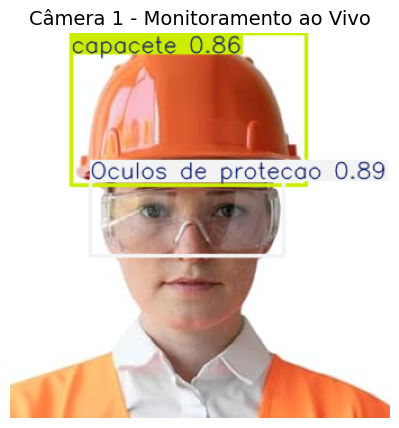

In [14]:
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from ultralytics import YOLO

# 1. Carregue o seu modelo treinado (ajuste o nome do arquivo se necessário)
model = YOLO('/content/best.pt')

image_path = '/content/EPI.png'

# 2. Defina os EPIs que o sistema obrigatoriamente precisa encontrar
# Os nomes devem ser escritos exatamente como as classes do seu modelo
epis_obrigatorios = ['capacete', 'Oculos de protecao', 'mascara', 'colete']

# Variável para passar os dados para a Célula 4
epis_faltantes = []

try:
    # Inferência
    results = model(image_path)
    img_bgr = results[0].plot()
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # 3. Extração dinâmica das classes que a IA detectou na imagem
    nomes_classes = results[0].names
    classes_detectadas_ids = results[0].boxes.cls.tolist()

    # Cria uma lista apenas com os nomes do que foi encontrado
    itens_detectados = [nomes_classes[int(id)] for id in classes_detectadas_ids]

    # Exibição da Imagem
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(img_rgb)
    ax.axis('off')
    ax.set_title("Câmera 1 - Monitoramento ao Vivo", fontsize=14)
    plt.show()

    # 4. Geração Dinâmica do HTML
    html_pills = """
    <div style='background-color: #333; padding: 15px; color: white; width: 350px; border-radius: 8px; font-family: sans-serif;'>
        <h4 style='margin-top: 0;'>Status dos EPIs (Câmera 1):</h4>
    """

    for epi in epis_obrigatorios:
        if epi in itens_detectados:
            html_pills += f"<p><span style='background-color: #28a745; padding: 5px 10px; border-radius: 15px; display: inline-block; margin-bottom: 5px;'>{epi.capitalize()} (Detectado)</span></p>"
        else:
            html_pills += f"<p><span style='background-color: #dc3545; padding: 5px 10px; border-radius: 15px; display: inline-block; margin-bottom: 5px;'>{epi.capitalize()} (Faltante)</span></p>"
            epis_faltantes.append(epi.capitalize()) # Guarda para a próxima etapa

    html_pills += "</div>"

    display(HTML(html_pills))

except Exception as e:
    print(f"Erro ao processar: {e}")

In [15]:
if len(epis_faltantes) == 0:
    display(HTML("""
    <div style='background-color: #d4edda; padding: 15px; border-radius: 10px; border-left: 5px solid #28a745;'>
        <h4 style='color: #155724;'>✅ Conformidade Total</h4>
        <p style='color: #155724;'>O colaborador está utilizando todos os EPIs obrigatórios.</p>
    </div>
    """))
else:
    # Formata a lista de EPIs faltantes separados por vírgula
    lista_faltantes_str = ", ".join(epis_faltantes)

    html_alerta = f"""
    <div style='display: flex; gap: 20px; font-family: sans-serif;'>
        <div style='background-color: #f8f9fa; padding: 15px; border-radius: 10px; width: 45%; border-left: 5px solid red;'>
            <h4 style='color: black; margin-top: 0;'>🚨 Alerta de Risco</h4>
            <p style='color: black;'><b>Data/Hora:</b> 10/06/2026 - 13:15</p>
            <p style='color: black;'><b>Setor:</b> Linha de Montagem B</p>
            <p style='color: black;'><b>EPI Faltante:</b> {lista_faltantes_str}</p>
            <p style='color: black;'><b>Nível de Risco:</b> 🔴 ALTO / CRÍTICO</p>
        </div>

        <div style='background-color: #e9ecef; padding: 15px; border-radius: 10px; width: 45%;'>
            <h4 style='color: black; margin-top: 0;'>👤 Colaborador Identificado</h4>
            <p style='color: black;'><b>Nome:</b> Roberto Almeida</p>
            <p style='color: black;'><b>Cargo:</b> Técnico de Manutenção Elétrica</p>
            <p style='color: black;'><b>Matrícula:</b> #9021-MET</p>
            <p style='color: black;'><b>Status:</b> 🟢 ATIVO</p>
        </div>
    </div>
    """
    display(HTML(html_alerta))

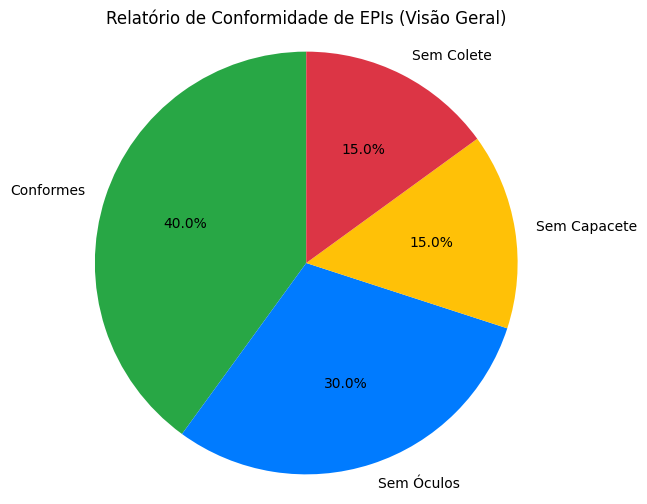

In [12]:
import matplotlib.pyplot as plt

labels = ['Conformes', 'Sem Óculos', 'Sem Capacete', 'Sem Colete']
sizes = [40, 30, 15, 15]
colors = ['#28a745', '#007bff', '#ffc107', '#dc3545']

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
ax.axis('equal')
plt.title('Relatório de Conformidade de EPIs (Visão Geral)')
plt.show()

In [13]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

btn_fornecido = widgets.Button(description='EPI Fornecido', button_style='success')
btn_advertencia = widgets.Button(description='Advertência Formalizada', button_style='warning')
btn_falso = widgets.Button(description='Falso Positivo (Erro IA)', button_style='danger')
output_tratativa = widgets.Output()

def registrar_tratativa(b):
    with output_tratativa:
        clear_output()
        # O print foi ajustado para evitar o erro de sintaxe e formatar a string corretamente
        print(f"Registro Salvo no sistema: {b.description} - Ocorrência Encerrada.")

btn_fornecido.on_click(registrar_tratativa)
btn_advertencia.on_click(registrar_tratativa)
btn_falso.on_click(registrar_tratativa)

display(HTML("<h3>Registrar Tratativa</h3>"))
display(widgets.HBox([btn_fornecido, btn_advertencia, btn_falso]))
display(output_tratativa)

Output()